# spSheaf tutorial: spatial domains from raw molecules

spSheaf infers spatial domains from a table of molecule detections — coordinates and gene identity — without segmenting cells. This notebook runs it on one public section, looks at every intermediate quantity, and shows what the parameters do and how to choose the number of domains.

The idea in one paragraph. Expression is smoothed onto a grid, so every grid point carries a *fiber* (a vector over genes). Around each grid point the fibers of its neighbourhood lie close to a low-dimensional subspace, the *stalk*; neighbouring stalks are aligned by a small orthogonal map, the *restriction map*. Inside a domain the aligned local coordinates of neighbouring grid points agree; across a transition between expression programs they do not, however the stalks are aligned. That residual *disagreement* is scored on every edge of the grid, smoothed into a field, and the field attenuates the transitions during clustering, so domains are cut where expression programs change rather than where expression merely varies.

Requirements: `pip install spsheaf matplotlib`. The data (~25 MB) downloads on first run.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from spsheaf import fibers, graph, sheaf, clustering, evaluation

DATA = Path("data_quickstart"); DATA.mkdir(exist_ok=True)
BASE = "https://s3.amazonaws.com/starfish.data.spacetx/spacetx-website/data/BARISTASeq"
for name in ("s3_spot_table.csv", "s3_mapped_cell_table.csv"):
    if not (DATA / name).exists():
        urlretrieve(f"{BASE}/{name}", DATA / name)

spots = pd.read_csv(DATA / "s3_spot_table.csv", usecols=["xc", "yc", "gene"])
mol = pd.DataFrame({"x": spots.xc.values, "y": spots.yc.values, "gene": spots.gene.astype(str).values})
mol.head()

,x,y,gene
0,702.343659,276.309096,Atp1a3
1,626.979243,232.644003,Adarb2
2,628.949805,233.780889,Sparcl1
3,631.764893,235.405013,Atp1a3
4,628.747387,233.479388,Sparcl1


## 1. The input

A molecule table with three columns: `x`, `y` (any unit; here micrometres) and `gene`. This is the SpaceTx BaristaSeq section of mouse visual cortex: 319,358 molecules of 81 genes, annotated by its authors into six layers (L1, L2/3, L4, L5, L6, white matter). The annotation is used only at the end, to score the result.

319,358 molecules, 81 genes, 802 x 1291 um


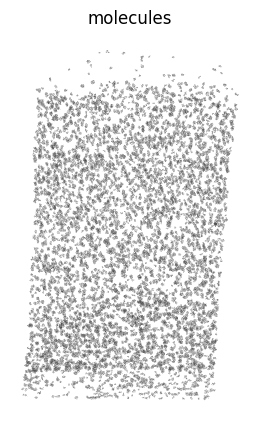

In [2]:
print(f"{len(mol):,} molecules, {mol.gene.nunique()} genes, "
      f"{np.ptp(mol.x):.0f} x {np.ptp(mol.y):.0f} um")
fig, ax = plt.subplots(figsize=(4, 5))
ax.scatter(mol.x, mol.y, s=0.05, c="#333333", linewidths=0, alpha=0.3)
ax.set_aspect("equal"); ax.set_axis_off(); ax.set_title("molecules")
plt.show()

## 2. Fibers: expression smoothed onto a grid

`build_kernel_fibers` places a square grid with spacing `grid_spacing` over the molecules and, at each grid point, counts the molecules of each gene with a Gaussian weight of bandwidth `bandwidth`. `normalize_fibers` turns the counts into proportions and applies log(1 + 1000 p), so a fiber describes *which* genes are present around that point, not how many molecules were detected.

The two lengths set the resolution: the grid spacing is the pixel size of the output; the bandwidth is how far a molecule influences a fiber, and should be a few cell diameters. Here 10 and 40 µm.

  Grid: 10,259 valid points, 81 genes
10,259 grid points x 81 genes


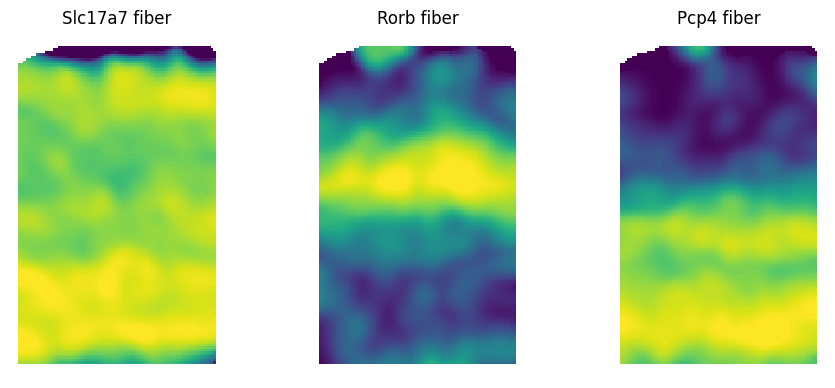

In [3]:
GRID_SPACING, BANDWIDTH = 10.0, 40.0
grid, raw, genes = fibers.build_kernel_fibers(mol, grid_spacing=GRID_SPACING, bandwidth=BANDWIDTH,
                                              x_col="x", y_col="y")
fib = fibers.normalize_fibers(raw)
print(f"{len(grid):,} grid points x {fib.shape[1]} genes")

def show(values, title, cmap="viridis", ax=None, s=4):
    ax = ax or plt.gca()
    lo, hi = np.nanpercentile(values, [2, 98])
    ax.scatter(grid[:, 0], grid[:, 1], c=values, cmap=cmap, s=s, marker="s", linewidths=0, vmin=lo, vmax=hi)
    ax.set_aspect("equal"); ax.set_axis_off(); ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.5))
for ax, g in zip(axes, ["Slc17a7", "Rorb", "Pcp4"]):
    show(fib[:, list(genes).index(g)], f"{g} fiber", ax=ax)
plt.show()

## 3. Graph, stalks and restriction maps

The grid points are joined into a `k`-nearest-neighbour graph (step 2). At every vertex the fibers of its 50 nearest grid points are fitted with a principal subspace of dimension `uniform_dim`: the **stalk**, a local coordinate system for expression around that point (step 3). For every edge, the two stalks are aligned by the orthogonal map that best matches them, obtained from an SVD (step 4). None of this uses the coordinates beyond the neighbourhoods; the sheaf lives in expression space over the spatial graph.

`uniform_dim` is the number of expression directions kept locally — enough to describe the programs present, few enough to be stable from 50 fibers. 6–9 covers the panels in the paper.

In [4]:
STALK_DIM = 9
edges = graph.build_spatial_graph(grid, k=6)
stalks = sheaf.compute_stalks(fib, grid, uniform_dim=STALK_DIM, k_nbrs=50)
rs = sheaf.compute_restriction_maps(stalks, edges, STALK_DIM)
print(f"{len(edges):,} edges; {len(stalks):,} stalks of {np.asarray(stalks[0]).shape[1]} directions each; one restriction map per edge end")

  Spatial graph: 10259 vertices, 35807 edges, mean degree 7.0


  Stalks: 10259 vertices, uniform dim = 9


  Restriction maps: 35807 edges
35,807 edges; 10,259 stalks of 9 directions each; one restriction map per edge end


## 4. The disagreement field

For an edge (u, v), each fiber is written in its own stalk's coordinates, the two coordinate vectors are carried onto the edge by the restriction maps, and the squared distance between them is the edge's **disagreement** (step 5). It is near zero inside a domain, where the neighbouring programs are the same up to the alignment, and large across a transition. Summing over the edges at each vertex and smoothing with a Gaussian of radius `smooth_radius` gives the field (step 6).

`smooth_radius` sets how wide a transition is attenuated: a few grid spacings on a benchmark with sharp nuclei (60 µm at 15-µm spacing), more on laminar cortex, where it was tuned to 180 µm.

  Boundary scores (tissue reference): mean=0.5174, max=1.2468 (0.2s)


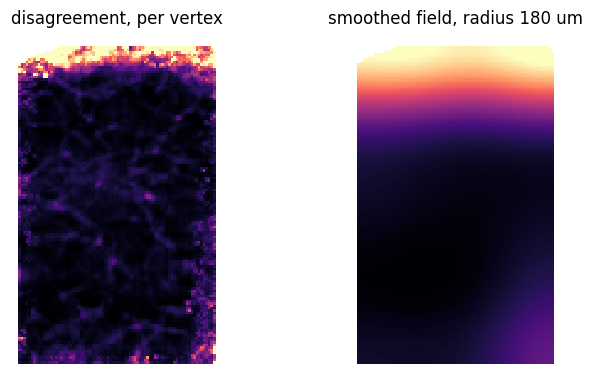

In [5]:
SMOOTH_RADIUS = 180.0
b_raw, b_smooth = sheaf.compute_boundary_scores(fib, grid, stalks, edges, rs, smooth_radius=SMOOTH_RADIUS)
fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
show(b_raw, "disagreement, per vertex", cmap="magma", ax=axes[0])
show(b_smooth, f"smoothed field, radius {SMOOTH_RADIUS:.0f} um", cmap="magma", ax=axes[1])
plt.show()

## 5. Clustering with the field, and clean-up

Each grid point gets a feature: its normalised fiber scaled down where the field is high (`boundary_alpha` sets how strongly), concatenated with its coordinates weighted by `spatial_weight`. k-means on that feature gives `n_clusters` domains (step 7); `spatial_cleanup` reassigns fragments below 1 % of the grid to their neighbours (step 8).

`n_clusters` is the number of domains and must be given; section 7 shows how to choose it without an annotation.

  Clusters (6): [3175, 1968, 1924, 1724, 855, 613]


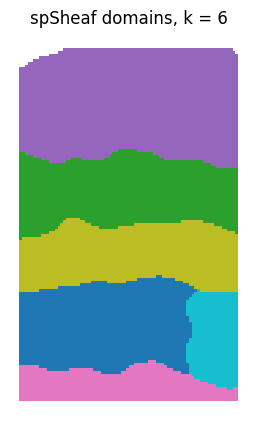

In [6]:
K, SPATIAL_WEIGHT, BOUNDARY_ALPHA = 6, 0.5, 0.5
labels = clustering.boundary_aware_clustering(fib, grid, b_smooth, edges, n_clusters=K,
                                              spatial_weight=SPATIAL_WEIGHT, boundary_alpha=BOUNDARY_ALPHA)
labels, _ = clustering.spatial_cleanup(labels, edges, grid_coords=grid)
fig, ax = plt.subplots(figsize=(4, 5))
ax.scatter(grid[:, 0], grid[:, 1], c=labels, cmap="tab10", s=4, marker="s", linewidths=0)
ax.set_aspect("equal"); ax.set_axis_off(); ax.set_title(f"spSheaf domains, k = {K}")
plt.show()

## 6. Against the authors' annotation

The cell table of the dataset carries a layer label per cell. Cells are placed in the grid's frame and take the label of their nearest grid point; the Adjusted Rand Index compares the two labellings. The paper reports 0.757 for this section at this configuration (after a label-free registration of the cell frame; a corner alignment is used here), against 0.738 for the best competing method.

In [7]:
from scipy.spatial import cKDTree
cells = pd.read_csv(DATA / "s3_mapped_cell_table.csv")
cxy = cells[["rotated_x", "rotated_y"]].values
cxy = cxy - cxy.min(0) + grid.min(0)
pred = labels[cKDTree(grid).query(cxy, k=1)[1]]
names = sorted(cells.layer.dropna().unique())
gti = np.array([names.index(l) if isinstance(l, str) else -1 for l in cells.layer]); valid = gti >= 0
print(f"ARI {evaluation.compute_ari(pred, gti, valid):.3f}   NMI {evaluation.compute_nmi(pred, gti, valid):.3f}")
matched = evaluation.hungarian_match_labels(pred, gti, valid)
for i, n in enumerate(names):
    m = valid & (gti == i)
    print(f"  {n:14s} {m.sum():5d} cells   recall {np.mean(matched[m] == i):.2f}")

ARI 0.766   NMI 0.776
  L1                32 cells   recall 0.00
  L2/3            1065 cells   recall 0.94
  L4               997 cells   recall 0.96
  L5               906 cells   recall 0.80
  L6              1165 cells   recall 0.80
  Lwm              267 cells   recall 0.94


Layer 1 (32 cells, 0.7 % of the section) is not recovered: at k = 6 the sixth cluster goes to a patch within L6 instead. That is a property of fixing k at the annotated count when one domain is very small; the paper discusses it.

## 7. Choosing the number of domains

Without an annotation, compute the silhouette width of the normalised fibers under the partition for a range of k and select within the range where it lies within 0.002 of its maximum. On the paper's benchmark that range contained the annotated count on four of five sections and was within two of it on the fifth.

In [8]:
from sklearn.metrics import silhouette_score
rng = np.random.default_rng(0)
sub = rng.choice(len(grid), min(5000, len(grid)), replace=False)   # silhouette is O(n^2); a sample suffices
sil = {}
for k in range(3, 10):
    lab_k = clustering.boundary_aware_clustering(fib, grid, b_smooth, edges, n_clusters=k,
                                                 spatial_weight=SPATIAL_WEIGHT, boundary_alpha=BOUNDARY_ALPHA,
                                                 verbose=False)
    sil[k] = silhouette_score(fib[sub], lab_k[sub])
best = max(sil.values())
print({k: round(v, 4) for k, v in sil.items()})
print("within 0.002 of the maximum:", [k for k, v in sil.items() if v >= best - 0.002])

{3: 0.2025, 4: 0.202, 5: 0.2032, 6: 0.1854, 7: 0.1831, 8: 0.1681, 9: 0.1436}
within 0.002 of the maximum: [3, 4, 5]


On this section the range is 3–5, one below the annotated six: Layer 1 is 32 cells and no method recovers it, and at k = 5 the five remaining layers are recovered cleanly (ARI 0.78 in the paper). The silhouette identifies a narrow range of k, not a value; the annotation is the arbiter where one exists.

## 8. The same in one call

`pipeline.run_single_slice` runs the eight steps and, if the molecule table carries cell columns and a `domain` column (the MERFISH benchmark's schema), the evaluation at cell level. For a plain molecule table it returns the grid, the field and the labels.

Two settings are environment-level. `SPSHEAF_REFERENCE=tissue|local` chooses the reference point of the local coordinates (the section mean, the default, or the neighbourhood mean); it is part of the tuning grid in the paper and the local reference is selected on the MERFISH benchmark only. `SPSHEAF_DATA` points the experiments of the repository at a data root; the package itself does not need it.

In [9]:
from spsheaf import pipeline
res = pipeline.run_single_slice(mol.assign(matched_h5ad_file="section"), slice_name="section",
                                n_clusters=K, grid_spacing=GRID_SPACING, bandwidth=BANDWIDTH,
                                uniform_dim=STALK_DIM, smooth_radius=SMOOTH_RADIUS,
                                spatial_weight=SPATIAL_WEIGHT, boundary_alpha=BOUNDARY_ALPHA,
                                eval_at_cell_level=False, verbose=False)
print(sorted(res.keys())[:12])
print("same partition as above:", evaluation.compute_ari(res["labels"], labels) > 0.99)

['ari', 'boundary_raw', 'boundary_smooth', 'cell_coords', 'cell_gt_int', 'cell_gt_names', 'cell_predicted', 'fibers_norm', 'grid_coords', 'gt_int', 'gt_names', 'gt_valid']
same partition as above: True


## Parameters at a glance

| parameter | meaning | paper's MERFISH value | this section |
|---|---|---|---|
| `grid_spacing` δ | pixel size of the output | 15 µm | 10 µm |
| `bandwidth` h | kernel width of the fibers; a few cell diameters | 25 µm | 40 µm |
| `uniform_dim` d | dimension of every stalk | 6 | 9 |
| `smooth_radius` σ_s | smoothing of the field; the width of a transition | 60 µm | 180 µm |
| `spatial_weight` α_s | weight of the coordinates in the clustering feature | 0.5 | 0.5 |
| `boundary_alpha` α_b | strength of the attenuation | 0.5 | 0.5 |
| `n_clusters` k | number of domains | 8 (annotated) | 6 (annotated) |
| `SPSHEAF_REFERENCE` | reference of the local coordinates | local (selected) | tissue (default) |

Runtime is linear in grid points and edges: about 30 s for a MERFISH section of 14,000 grid points on one core.